# 2026 DL Lab5: Object Detection on COCO 2017

Before we start, please put **your name** and **SID** in following format: <br>
Hi I'm 陸仁賈, 315831000.

**Your Answer:**    
Hi I'm 黃毓峰, 315834011.

## Overview

Train a three-scale YOLOv3 detector to locate and classify objects from 20 COCO categories.

Use the training set to learn model parameters and the validation set to select your model.

Implement the detection neck and head in `src/yolo.py`. Do not use COCO-pretrained detectors.

Only weights pretrained through supervised ImageNet classification are allowed.

## Dataset

Download `dataset.zip` and extract it. The dataset ZIP contains:

- `images/`: images for all splits.

- `train.txt`: list for the training set.

- `val.txt`: list for the validation set.

- `test.txt`: list for the test set.

COCO 2017 subset with 20 categories: **10,193 Train**, **3,397 Validation** and **9,060 Test** images.


## Import Packages

In [1]:
import random
from pathlib import Path

import torch
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from torch.amp import autocast, GradScaler
from torch.optim.lr_scheduler import CosineAnnealingLR
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

from src.config import ANCHORS, CLASS_NAMES, IMG_MEAN, IMG_STD, MODEL_NAME, YOLO_IMG_DIM
from src.dataset import CocoDetectorDataset, collate_fn
from src.evaluate import evaluate
from src.yolo import getODmodel
from src.yolo_loss import YOLOv3Loss

## Hyperparameters

In [2]:
# Training settings.
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
num_epochs = 50
image_size = YOLO_IMG_DIM
batch_size = 16
num_workers = 4
learning_rate = 1e-4
weight_decay = 5e-4
eval_interval = 5
use_amp = device.type == "cuda"

# Loss weights.
lambda_coord = 5.0
lambda_obj = 1.0
lambda_noobj = 0.5
lambda_class = 1.0

# Set random seeds.
seed = 2026
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

## Path & Config

In [3]:
# Dataset paths.
data_root = Path("dataset")
train_list_file = data_root / "train.txt"
val_list_file = data_root / "val.txt"

# Model settings and checkpoint paths.
model_name = MODEL_NAME
pretrained = True
checkpoint_dir = Path("checkpoints")
load_network_path = None

## Dataset & DataLoader

`train_loader` and `val_loader` return encoded targets for loss computation.

`eval_loader` returns the original image information needed for COCO evaluation.

In [4]:
# Train
train_dataset = CocoDetectorDataset(
    root=data_root,
    list_file=train_list_file,
    train=True,
    encode_target=True,
    image_size=image_size,
)
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=num_workers,
    collate_fn=collate_fn,
    pin_memory=device.type == "cuda",
)

# Validation
val_dataset = CocoDetectorDataset(
    root=data_root,
    list_file=val_list_file,
    train=False,
    encode_target=True,
    image_size=image_size,
)
val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=num_workers,
    collate_fn=collate_fn,
    pin_memory=device.type == "cuda",
)

print(f"Train: {len(train_dataset):,} images")
print(f"Validation: {len(val_dataset):,} images")
print(f"Classes: {len(CLASS_NAMES)}")

Train: 10,193 images
Validation: 3,397 images
Classes: 20


## Inspect an Annotated Image

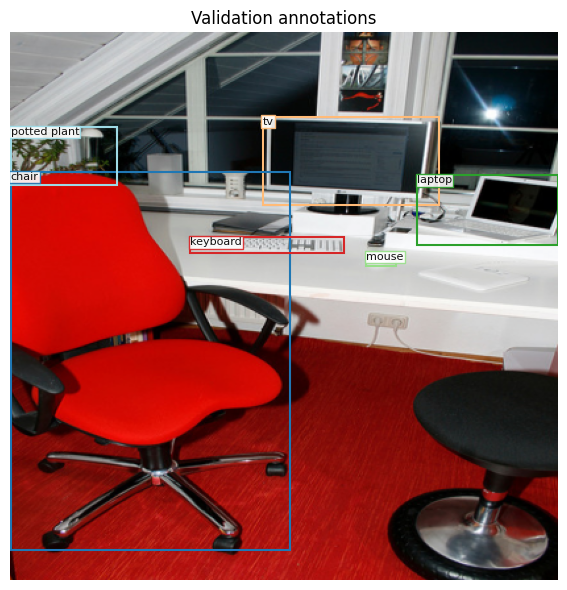

In [5]:
def draw_boxes(axis, image, boxes, labels):
    image_height, image_width = image.shape[:2]
    colors = plt.get_cmap("tab20")
    axis.imshow(image)

    for box, label in zip(boxes, labels):
        # Convert normalized xyxy boxes to pixels for display.
        x1, y1, x2, y2 = box * [image_width, image_height, image_width, image_height]
        color = colors(int(label))
        axis.add_patch(
            Rectangle(
                (x1, y1),
                x2 - x1,
                y2 - y1,
                fill=False,
                edgecolor=color,
                linewidth=1.5,
            )
        )
        axis.text(
            x1,
            y1,
            CLASS_NAMES[int(label)],
            fontsize=8,
            color="#111111",
            va="top",
            bbox={"facecolor": "white", "edgecolor": color, "alpha": 0.9, "pad": 1},
            clip_on=True,
        )

    axis.axis("off")


# Undo normalization to display RGB images.
image_tensor, _, example = val_dataset[0]
image_rgb = image_tensor.permute(1, 2, 0).numpy()
image_rgb = (image_rgb * np.array(IMG_STD) + np.array(IMG_MEAN)).clip(0, 1)

figure, axis = plt.subplots(figsize=(9, 6))
draw_boxes(axis, image_rgb, example["boxes"], example["labels"])
for x1, y1, x2, y2 in example["crowd_boxes"] * image_rgb.shape[0]:
    axis.add_patch(
        Rectangle(
            (x1, y1),
            x2 - x1,
            y2 - y1,
            fill=False,
            edgecolor="#444444",
            linestyle="--",
            linewidth=2,
        )
    )
axis.set_title("Validation annotations")
figure.tight_layout()
plt.show()
plt.close(figure)

## Load Model

The backbone provides stride 32/16/8 feature maps.

The detection head returns `(N, 13, 13, 75)`, `(N, 26, 26, 75)` and `(N, 52, 52, 75)` predictions, where `75 = 3 × (5 + 20)`.

Set `load_network_path` to load model weights. This initializes model parameters.

In [6]:
model = getODmodel(
    pretrained=pretrained and load_network_path is None,
    model_name=model_name,
).to(device)

if load_network_path is not None:
    state_dict = torch.load(load_network_path, map_location="cpu", weights_only=True)
    model.load_state_dict(state_dict)

print(f"Device: {device}")
print(f"Backbone: {model_name}")
print(f"Parameters: {sum(parameter.numel() for parameter in model.parameters()):,}")

Device: cuda:0
Backbone: darknet53.c2ns_in1k
Parameters: 61,626,049


## Loss, Optimizer & Scheduler

Each target contains `[tx, ty, w, h, obj, one-hot classes]`. 

The loss combines GIoU localization, focal objectness, and cross-entropy classification.

In [7]:
# Create the loss function.
criterion = YOLOv3Loss(
    lambda_coord=lambda_coord,
    lambda_obj=lambda_obj,
    lambda_noobj=lambda_noobj,
    lambda_class=lambda_class,
    anchors=ANCHORS,
).to(device)

# AdamW optimizer and cosine learning-rate schedule.
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=learning_rate,
    weight_decay=weight_decay,
)
lr_scheduler = CosineAnnealingLR(optimizer, T_max=num_epochs, eta_min=1e-6)
scaler = GradScaler("cuda", enabled=use_amp)

## Training Loop

Train on the full training set and compute validation loss after every epoch.

Save the best model according to validation loss, and evaluate COCO bbox AP every `eval_interval` epochs.

- `best_detector.pth` contains the best model weights.

- `detector.pth` contains the latest model weights.

In [8]:
checkpoint_dir.mkdir(parents=True, exist_ok=True)
best_val_loss = float("inf")
history = []

for epoch in range(num_epochs):
    # Training
    model.train()
    train_loss = 0.0
    train_images = 0
    current_lr = optimizer.param_groups[0]["lr"]
    progress = tqdm(train_loader, desc=f"Train {epoch + 1}/{num_epochs}", leave=False)

    for images, targets, _ in progress:
        images = images.to(device, non_blocking=True)
        targets = [target.to(device, non_blocking=True) for target in targets]
        optimizer.zero_grad(set_to_none=True)

        with autocast(device.type, enabled=use_amp):
            predictions = model(images)

        loss_dict = criterion(predictions, targets)
        if not torch.isfinite(loss_dict["total"]):
            raise FloatingPointError("Training loss is not finite.")

        scaler.scale(loss_dict["total"]).backward()
        scaler.step(optimizer)
        scaler.update()

        train_loss += loss_dict["total"].detach().item() * len(images)
        train_images += len(images)
        progress.set_postfix(loss=f"{train_loss / train_images:.4f}")

    train_loss /= train_images
    lr_scheduler.step()

    # Validation
    model.eval()
    val_loss = 0.0
    val_images = 0

    with torch.no_grad():
        for images, targets, _ in val_loader:
            images = images.to(device, non_blocking=True)
            targets = [target.to(device, non_blocking=True) for target in targets]

            predictions = model(images)
            loss_dict = criterion(predictions, targets)
            if not torch.isfinite(loss_dict["total"]):
                raise FloatingPointError("Validation loss is not finite.")

            val_loss += loss_dict["total"].item() * len(images)
            val_images += len(images)

    val_loss /= val_images
    history.append({"epoch": epoch + 1, "train_loss": train_loss, "val_loss": val_loss})
    print(
        f"Epoch {epoch + 1}/{num_epochs} | "
        f"Train loss: {train_loss:.4f} | Val loss: {val_loss:.4f} | LR: {current_lr:.6f}"
    )

    # Save the latest weights and a separate copy when validation loss improves.
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), checkpoint_dir / "best_detector.pth")
    torch.save(model.state_dict(), checkpoint_dir / "detector.pth")

    # Compute validation AP in original coordinates with the official COCO evaluator.
    if (epoch + 1) % eval_interval == 0 or epoch + 1 == num_epochs:
        metrics = evaluate(
            model,
            val_loader,
            annotation_data=val_dataset.coco,
            category_ids=val_dataset.category_ids,
        )
        print(f"Validation AP: {metrics['AP']:.4f} | AP50: {metrics['AP50']:.4f}")


Train 1/50:   0%|          | 0/638 [00:00<?, ?it/s]

Epoch 1/50 | Train loss: 4.5026 | Val loss: 3.6830 | LR: 0.000100


Train 2/50:   0%|          | 0/638 [00:00<?, ?it/s]

Epoch 2/50 | Train loss: 3.3634 | Val loss: 3.1575 | LR: 0.000100


Train 3/50:   0%|          | 0/638 [00:00<?, ?it/s]

Epoch 3/50 | Train loss: 2.9448 | Val loss: 3.0070 | LR: 0.000100


... (110 outputs left out)

Train 50/50:   0%|          | 0/638 [00:00<?, ?it/s]

Epoch 50/50 | Train loss: 0.5112 | Val loss: 2.8436 | LR: 0.000001


COCO evaluation:   0%|          | 0/213 [00:00<?, ?it/s]

creating index...
index created!
Loading and preparing results...
DONE (t=0.31s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=6.40s).
Accumulating evaluation results...
DONE (t=1.81s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.113
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.243
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.096
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.030
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.126
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.238
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.165
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.264
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.284
 Average Recall     (AR) @[ IoU=0.5

## Kaggle Submission

Load a trained checkpoint and generate `result.csv` for all Test images.

Predictions use original-image coordinates, class-wise NMS, and at most 100 boxes per image.

In [9]:
from src.predict_test import predict_test

result_path = predict_test(
    weights_path=checkpoint_dir / "best_detector.pth",
    data_root=data_root,
    output_path=Path("result.csv"),
    batch_size=batch_size,
    device=device,
    model_name=model_name,
    image_size=image_size,
)

Predict test:   0%|          | 0/567 [00:00<?, ?it/s]

Wrote 9,060 images to result.csv


## Final Detector

The YOLOv3 cells above are the template with its TODO blocks filled in `src/yolo.py` and `src/yolo_loss.py` (run 001 of the report: validation AP 0.120). The cells below train the detector that replaced it, implemented from scratch in `src/`:

- `src/detector.py`: ImageNet-1k ConvNeXt backbone from timm (`*.fb_in1k`, supervised classification weights only, strides 8 / 16 / 32) -> PAFPN neck (C2f-style CSP blocks, 384 channels, depth 3) -> decoupled head that predicts class logits and a discrete distribution over the four box distances (DFL, 16 bins) per cell; anchor-free, multi-label scoring, class-aware NMS.
- `src/det_loss.py`: task-aligned assignment (top-10 cells per box by `score^0.5 * IoU^6`), BCE classification against the alignment scores, CIoU box loss and distribution focal loss (weights 0.5 / 7.5 / 1.5).
- `src/det_data.py`: letterbox, mosaic of four images on a 2x canvas, box-level copy-paste (up to 6 object crops from other images pasted on every mosaic), random affine, mixup between two mosaics, HSV jitter, horizontal flip; mosaic is switched off for the last 10 epochs.
- `src/det_train.py`: the training loop (`TrainConfig` holds every setting): batch-level multi-scale 0.6-1.25 of the letterbox size, AdamW with a 0.25x backbone learning rate, 3 warmup + cosine epochs, bf16 autocast, gradient checkpointing, EMA weights evaluated every 5 epochs.
- `src/det_eval.py`: COCO AP on original-image coordinates and the Kaggle CSV, with test-time augmentation (horizontal flip and two extra scales of the same model, pooled by one NMS). One model, no ensemble.

The recipe was chosen by one-change-at-a-time experiments on an RTX 3090 Ti (`scripts/train/001-017`, table in the report). Run 016 (ConvNeXt-B, 800 letterbox, batch 12, copy-paste on every mosaic, 40 epochs) reached validation AP 0.440, 0.458 with TTA at 896; run 017 showed that a 30-epoch cosine ends at its peak (last epoch 0.441, equal to the best), so the schedule can be fixed in advance. This notebook is one end-to-end run of that recipe on the 3090 Ti (ConvNeXt-B, 800 letterbox with multi-scale 480-1000, batch 12, 30 epochs) trained on train + val minus a seeded hold-out of 400 val images. Because the full validation set is no longer available for model selection, the schedule is fixed and the EMA weights of the last epoch are the model; the hold-out AP printed every 5 epochs is a (noisy) monitor only.

In [10]:
import json
from dataclasses import asdict, replace

from src.config import NUM_CLASSES
from src.det_eval import evaluate_detector, write_submission
from src.det_loss import DetectionLoss
from src.det_train import (
    TrainConfig,
    build_datasets,
    build_model,
    build_optimizer,
    make_loader,
    subset_coco,
    train_detector,
)

### Configuration

`TrainConfig()` defaults are the 3090 Ti recipe of run 015; the overrides below add run 016's copy-paste dose, the 30-epoch schedule of run 017 and the train + val split. Peak memory with gradient checkpointing is about 21 GB at batch 12 (inputs up to 1000), so it fills the 24 GB card; with 13,190 training images an epoch takes about 12 min, the whole run about 6.5 h. Training resumes from `checkpoints/final-last.pt` if the kernel is restarted.

In [11]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
data_root = Path("dataset")

# train_on_val: train on train.txt + val.txt minus a 400-image hold-out (seeded split, written to the run folder).
# select="last": the EMA weights of the last epoch are the model (no full validation set to pick an epoch).
cfg = TrainConfig(
    copy_paste=1.0,  # run 016: every mosaic, up to 6 crops (best 896 TTA, flatter plateau than 0.5)
    copy_paste_objects=6,
    epochs=30,  # run 017: the 30-epoch cosine ends at its peak
    train_on_val=True,
    select="last",
)

# Final evaluation and submission: 896 letterbox, horizontal flip and scales 0.75 / 1.1, pooled by one class-aware NMS
# (models trained with multi-scale up to 1000 scored best at 896 with this TTA, runs 008-017).
eval_image_size = 896
tta_scales = (0.75, 1.1)

# True runs the whole pipeline on a few images for 2 short epochs (pipeline check only).
smoke = False
if smoke:
    cfg = replace(cfg, batch_size=2, num_workers=2)

det_checkpoint_dir = Path("checkpoints")  # a run resumes from <run_name>-last.pt after a kernel restart
run_name = "final"
log_path = det_checkpoint_dir / f"{run_name}.log"  # the printed training lines are also appended here
RESULT_PATH = Path("result.csv")

print(json.dumps(asdict(cfg), indent=2))

{
  "seed": 2026,
  "image_size": 800,
  "multi_scale": [
    0.6,
    1.25
  ],
  "multi_scale_every": 10,
  "mosaic": 1.0,
  "mixup": 0.15,
  "copy_paste": 1.0,
  "copy_paste_objects": 6,
  "affine_scale": [
    0.5,
    1.5
  ],
  "affine_translate": 0.1,
  "close_mosaic": 10,
  "batch_size": 12,
  "num_workers": 12,
  "model_name": "convnext_base.fb_in1k",
  "width": 384,
  "depth": 3,
  "reg_max": 16,
  "drop_path_rate": 0.4,
  "grad_checkpointing": true,
  "top_k": 10,
  "alpha": 0.5,
  "beta": 6.0,
  "box_weight": 7.5,
  "cls_weight": 0.5,
  "dfl_weight": 1.5,
  "epochs": 30,
  "warmup_epochs": 3,
  "lr": 0.0004,
  "backbone_lr_mult": 0.25,
  "min_lr": 1e-06,
  "weight_decay": 0.05,
  "grad_clip": 10.0,
  "ema_decay": 0.9998,
  "ema_tau": 2000,
  "eval_interval": 5,
  "conf_thres": 0.001,
  "nms_thres": 0.65,
  "train_on_val": true,
  "holdout": 400,
  "select": "last"
}


### Dataset & DataLoader

`DetectionDataset` returns the letterboxed image, an `(n, 5)` target `[class, x1, y1, x2, y2]` in input pixels and the metadata needed to map boxes back to the original image. With `cfg.train_on_val` the training list is train.txt plus val.txt minus the hold-out (`trainval.txt` / `holdout.txt` in the run folder); the hold-out is the validation set of the cells below.

`train_detector` builds its own training and validation loaders from `cfg`; the loaders here are for the final evaluation and the Kaggle submission at `eval_image_size`.

In [12]:
det_checkpoint_dir.mkdir(parents=True, exist_ok=True)
train_dataset, val_dataset, test_dataset = build_datasets(cfg, data_root, split_dir=det_checkpoint_dir)

eval_cfg = replace(cfg, image_size=eval_image_size)
_, val_eval_dataset, test_eval_dataset = build_datasets(eval_cfg, data_root, split_dir=det_checkpoint_dir)
limit = 32 if smoke else None
val_loader = make_loader(val_eval_dataset, eval_cfg, shuffle=False, limit=limit)
test_loader = make_loader(test_eval_dataset, eval_cfg, shuffle=False, limit=limit)
val_annotations = subset_coco(val_eval_dataset, limit) if smoke else val_eval_dataset.coco

print(f"Train (train + val minus hold-out): {len(train_dataset):,} images")
print(f"Validation (hold-out): {len(val_dataset):,} images")
print(f"Test: {len(test_dataset):,} images")
print(f"Classes: {NUM_CLASSES}")

Train (train + val minus hold-out): 13,190 images
Validation (hold-out): 400 images
Test: 9,060 images
Classes: 20


### Inspect an Annotated Image

Left: a hold-out image letterboxed to the training size with its ground-truth boxes. Right: a training sample after mosaic, copy-paste, random affine, HSV jitter and flip (and mixup with a second mosaic when drawn).

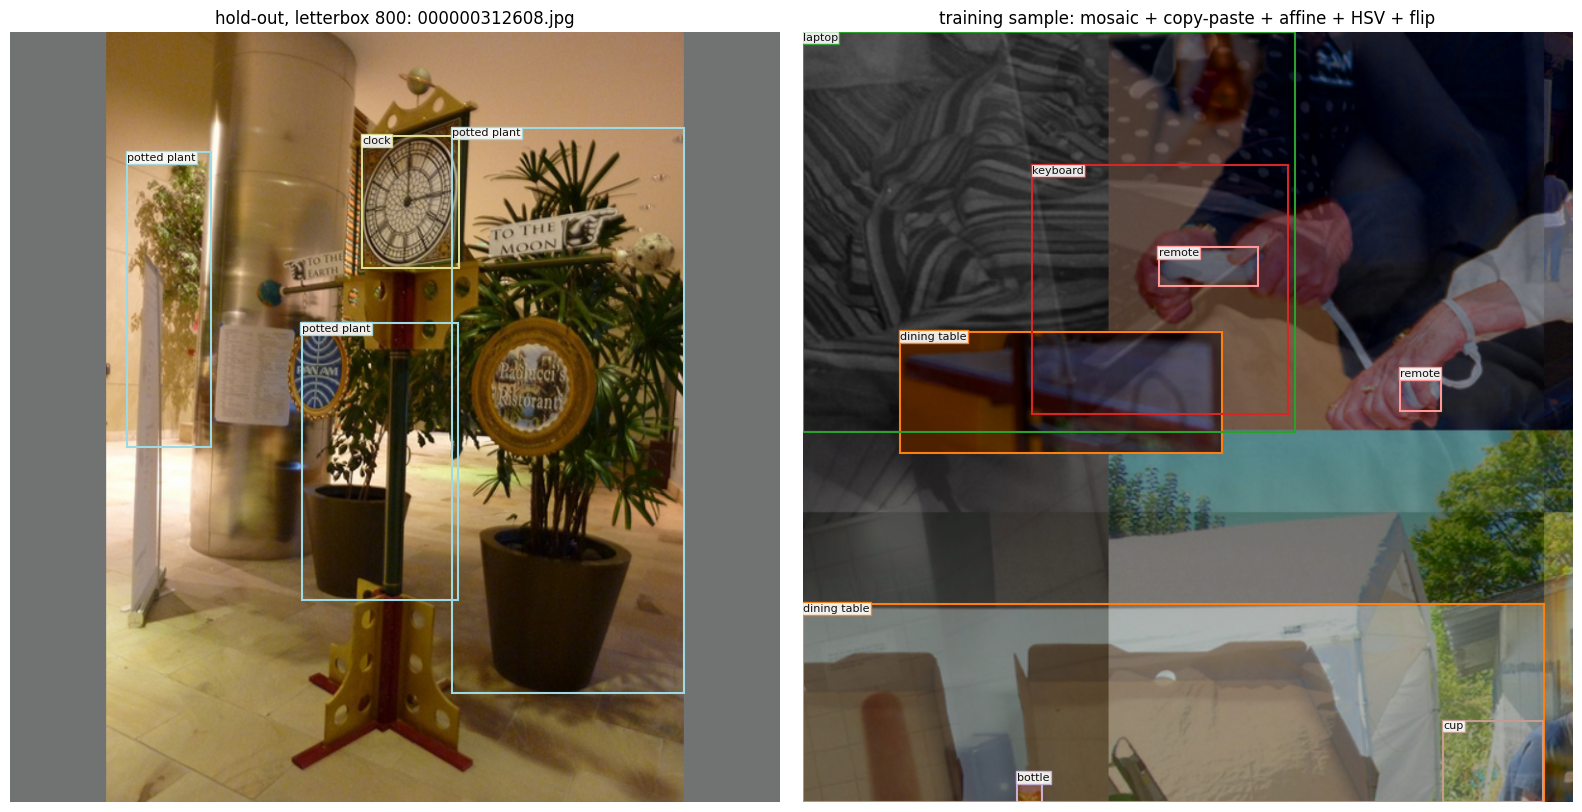

In [13]:
def to_rgb(image_tensor: torch.Tensor) -> np.ndarray:
    image = image_tensor.permute(1, 2, 0).numpy()
    return (image * np.array(IMG_STD) + np.array(IMG_MEAN)).clip(0, 1)


def draw_target(axis, image: np.ndarray, target: torch.Tensor, title: str) -> None:
    colors = plt.get_cmap("tab20")
    axis.imshow(image)
    for label, x1, y1, x2, y2 in target.tolist():
        color = colors(int(label))
        axis.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=color, linewidth=1.5))
        axis.text(
            x1,
            y1,
            CLASS_NAMES[int(label)],
            fontsize=8,
            color="#111111",
            va="top",
            bbox={"facecolor": "white", "edgecolor": color, "alpha": 0.9, "pad": 1},
            clip_on=True,
        )
    axis.set_title(title)
    axis.axis("off")


random.seed(cfg.seed)
np.random.seed(cfg.seed)
val_image, val_target, val_metadata = val_dataset[0]
train_image, train_target, _ = train_dataset[0]

figure, axes = plt.subplots(1, 2, figsize=(16, 8))
draw_target(axes[0], to_rgb(val_image), val_target, f"hold-out, letterbox {cfg.image_size}: {val_metadata['file_name']}")
draw_target(axes[1], to_rgb(train_image), train_target, "training sample: mosaic + copy-paste + affine + HSV + flip")
plt.tight_layout()
plt.show()

### Model

`Detector` = timm backbone (strides 8 / 16 / 32, ImageNet-1k weights) -> PAFPN -> decoupled head. The forward pass returns, flattened over the three levels, class logits `(N, A, 20)` and DFL logits `(N, A, 4 * 16)` together with the cell centres and strides; `inference` decodes them to boxes and runs class-aware NMS.

In [14]:
model = build_model(cfg, pretrained=True).to(device)

with torch.no_grad():
    outputs = model(torch.zeros(1, 3, cfg.image_size, cfg.image_size, device=device))

print(f"Device: {device}")
print(f"Backbone: {cfg.model_name}, feature channels {model.backbone.channels}")
print(f"Parameters: {sum(parameter.numel() for parameter in model.parameters()):,}")
print(f"Outputs at {cfg.image_size}: cls {tuple(outputs['cls'].shape)}, reg {tuple(outputs['reg'].shape)}")

Device: cuda:0
Backbone: convnext_base.fb_in1k, feature channels (256, 512, 1024)
Parameters: 117,574,268
Outputs at 800: cls (1, 13125, 20), reg (1, 13125, 64)


### Loss, Optimizer & Scheduler

Targets are assigned by the task-aligned assigner inside `DetectionLoss`; the loss is BCE against the alignment scores plus CIoU and DFL over the positive cells, normalised by the sum of target scores.

AdamW with a 0.25x learning rate on the backbone and no weight decay on norms and biases; 3 warmup epochs, then cosine to `min_lr`, stepped every iteration. The EMA of the weights is what gets evaluated and saved.

In [15]:
criterion = DetectionLoss(
    num_classes=NUM_CLASSES,
    reg_max=cfg.reg_max,
    box_weight=cfg.box_weight,
    cls_weight=cfg.cls_weight,
    dfl_weight=cfg.dfl_weight,
    top_k=cfg.top_k,
    alpha=cfg.alpha,
    beta=cfg.beta,
)
optimizer = build_optimizer(model, cfg)
for group in optimizer.param_groups:
    count = sum(parameter.numel() for parameter in group["params"])
    print(f"lr {group['lr']:.1e} | weight decay {group['weight_decay']:.2f} | {count:,} parameters")

# train_detector rebuilds the model, loss, optimizer and EMA from cfg (so a run can resume from <run_name>-last.pt).
del model, optimizer

lr 1.0e-04 | weight decay 0.05 | 87,398,016 parameters
lr 1.0e-04 | weight decay 0.00 | 166,400 parameters
lr 4.0e-04 | weight decay 0.05 | 29,981,184 parameters
lr 4.0e-04 | weight decay 0.00 | 28,668 parameters


### Training Loop

`train_detector` trains for `cfg.epochs` epochs with batch-level multi-scale and evaluates the EMA weights on the hold-out every `cfg.eval_interval` epochs; with `select = "last"` the EMA weights of the last epoch are the model (the `*` marks the evaluation whose weights were saved).

- `<run folder>/final.pt` contains the model weights (EMA, last epoch).
- `<run folder>/final-last.pt` contains the latest state (model, optimizer, EMA, history); re-running this cell resumes from it.

In [16]:
def log(message: str) -> None:
    print(message, flush=True)
    with log_path.open("a", encoding="utf-8") as stream:
        stream.write(message + "\n")


model, history = train_detector(
    cfg=cfg,
    data_root=data_root,
    checkpoint_dir=det_checkpoint_dir,
    run_name=run_name,
    device=device,
    log=log,
    smoke=smoke,
)

[final] config: {"seed": 2026, "image_size": 800, "multi_scale": [0.6, 1.25], "multi_scale_every": 10, "mosaic": 1.0, "mixup": 0.15, "copy_paste": 1.0, "copy_paste_objects": 6, "affine_scale": [0.5, 1.5], "affine_translate": 0.1, "close_mosaic": 10, "batch_size": 12, "num_workers": 12, "model_name": "convnext_base.fb_in1k", "width": 384, "depth": 3, "reg_max": 16, "drop_path_rate": 0.4, "grad_checkpointing": true, "top_k": 10, "alpha": 0.5, "beta": 6.0, "box_weight": 7.5, "cls_weight": 0.5, "dfl_weight": 1.5, "epochs": 30, "warmup_epochs": 3, "lr": 0.0004, "backbone_lr_mult": 0.25, "min_lr": 1e-06, "weight_decay": 0.05, "grad_clip": 10.0, "ema_decay": 0.9998, "ema_tau": 2000, "eval_interval": 5, "conf_thres": 0.001, "nms_thres": 0.65, "train_on_val": true, "holdout": 400, "select": "last"}
train 13,190 | val 400
params 117.57M (backbone 87.56M) | convnext_base.fb_in1k
resumed from final-last.pt at epoch 5
  epoch 6 step 0/1099 | loss 4.143 | box 0.160 cls 3.171 dfl 0.903 | fg 846 | siz

### Training Curves

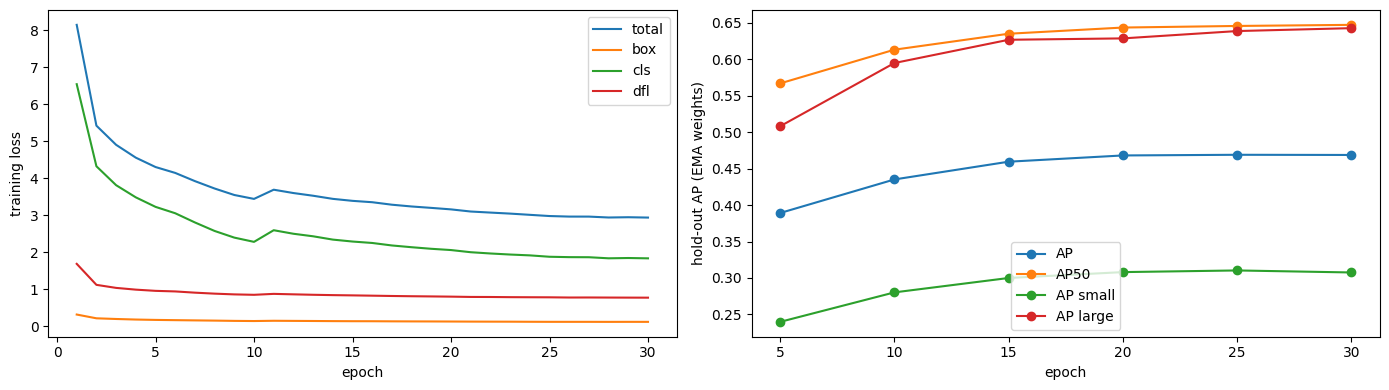

In [17]:
epochs = [record["epoch"] for record in history]
evaluated = [record for record in history if "AP" in record]

figure, axes = plt.subplots(1, 2, figsize=(14, 4))
for key in ("train_total", "train_box", "train_cls", "train_dfl"):
    axes[0].plot(epochs, [record[key] for record in history], label=key.removeprefix("train_"))
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("training loss")
axes[0].legend()
for key, label in (("AP", "AP"), ("AP50", "AP50"), ("AP_small", "AP small"), ("AP_large", "AP large")):
    axes[1].plot([record["epoch"] for record in evaluated], [record[key] for record in evaluated], marker="o", label=label)
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("hold-out AP (EMA weights)")
axes[1].legend()
plt.tight_layout()
plt.show()

### Kaggle Submission (final detector)

Load the final checkpoint, measure the hold-out AP at `eval_image_size` without and with test-time augmentation, and write `result.csv` for all test images with the augmented setting (this file replaces the YOLOv3 one written above).

Predictions use original-image coordinates, class-wise NMS, and at most 100 boxes per image.

In [18]:
model = build_model(cfg, pretrained=False).to(device).eval()
model.load_state_dict(torch.load(det_checkpoint_dir / f"{run_name}.pt", map_location="cpu", weights_only=True))

settings = {
    "plain": {"hflip_tta": False, "tta_scales": ()},
    f"hflip + scales {tta_scales}": {"hflip_tta": True, "tta_scales": tta_scales},
}
for name, tta in settings.items():
    metrics = evaluate_detector(
        model,
        val_loader,
        annotation_data=val_annotations,
        category_ids=val_eval_dataset.category_ids,
        conf_thres=cfg.conf_thres,
        nms_thres=cfg.nms_thres,
        **tta,
    )
    print(
        f"hold-out @{eval_image_size} {name}: AP {metrics['AP']:.4f} | AP50 {metrics['AP50']:.4f}"
        f" | AP75 {metrics['AP75']:.4f} | APs {metrics['AP_small']:.4f} | APm {metrics['AP_medium']:.4f}"
        f" | APl {metrics['AP_large']:.4f}"
    )
print("per-class AP: " + ", ".join(f"{k} {v:.3f}" for k, v in metrics["per_class_ap"].items() if v is not None))

result_path = write_submission(
    model,
    test_loader,
    output_path=RESULT_PATH,
    conf_thres=cfg.conf_thres,
    nms_thres=cfg.nms_thres,
    hflip_tta=True,
    tta_scales=tta_scales,
)

creating index...
index created!
Loading and preparing results...
DONE (t=0.01s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=0.76s).
Accumulating evaluation results...
DONE (t=0.18s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.471
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.649
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.516
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.327
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.510
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.628
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.383
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.609
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.644
 Average Recall     (AR) @[ IoU=0.5